<a href="https://colab.research.google.com/github/oyrslufe/ESAA/blob/main/ESAA%201012%20assignment13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 4. 딥러닝 시작
### 4.1 인공 신경망의 한계와 딥러닝 출현
퍼셉트론

- 다수의 신호(흐름이 있는)를 입력으로 받아 하나의 신호를 출력
- 이 신호를 입력으로 받아 '흐른다/안 흐른다(1또는 0)'는 정보를 앞으로 전달

입력값 : 다수의 신호

출력값 : 하나의 신호

정보 : '흐른다'(1)/'안 흐른다'(0)

AND 게이트

- AND 게이트는 모든 입력이 1일 때 작용

OR 게이트

- 둘 중 하나만 1이거나 둘 다 1일 때 작동. 즉 입력 모두가 0을 가지는 경우를 제외한 경우

XOR 게이트
- 배타적 논리합이라는 용어로 입력 두 개 중 한 개만 1일때 작용하는 논리 연산

- 데이터가 비선형적으로 분리되기 때문에 제대로 된 분류가 어려움.

### 4.2 딥러닝 구조
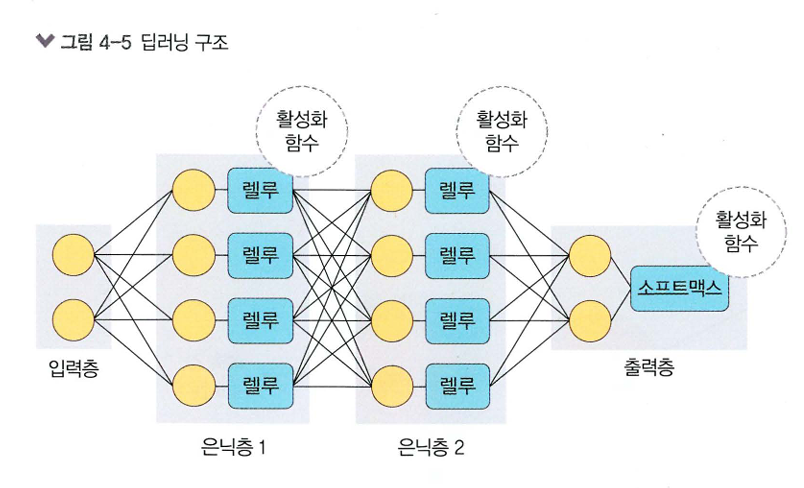

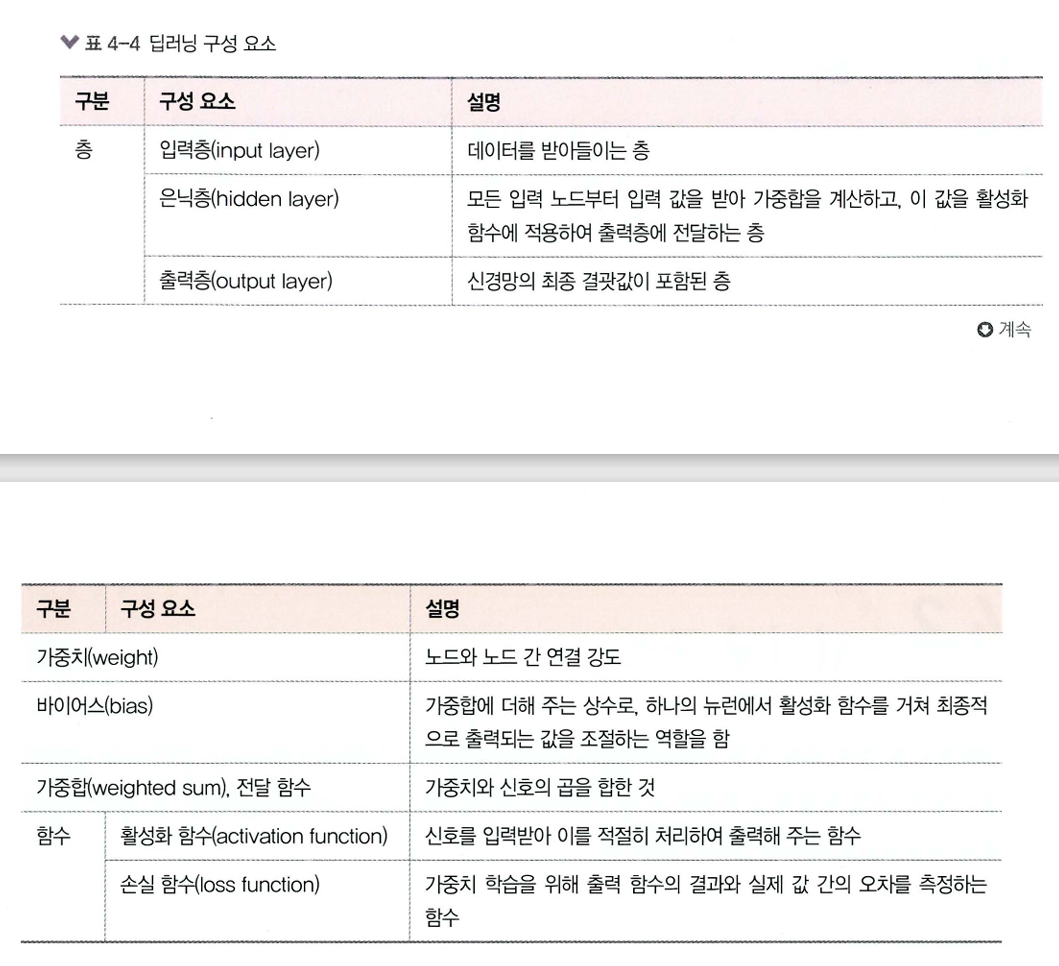

- 가중치

입력 값이 연산 결과에 미치는 영향력을 조절하는 요소


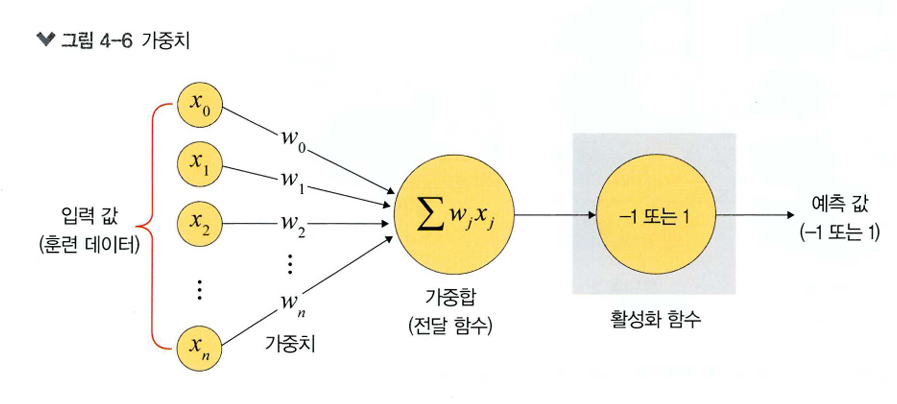


- 가중합 (전달 함수)

 각 노드에서 들어오는 신호에 가중치를 곱해서 다음 노드로 전달되는데 이 값들을 모두 더한 합계

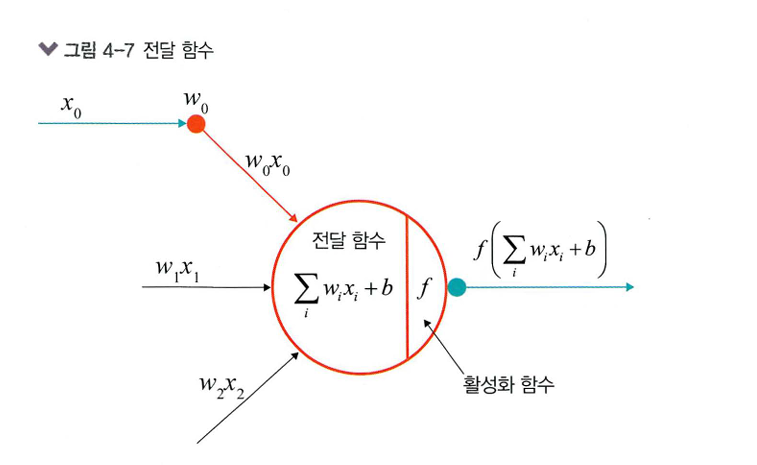

활성화 함수

- 전달 함수에서 전달받은 값을 출력할 때 일정 기준에 따라 출력 값을 변화시키는 비선형 함수
- 시그모이드, 하이퍼볼릭 탄젠트, 렐루 함수 등이 있음

시그모이드 함수

- 선형 함수의 결과를 0~1 사이에서 비선형 형태로 변형해 줌. 주로 로지스틱 회귀와 같은 분류 문제를 확률적으로 표현하는 데 사용됨

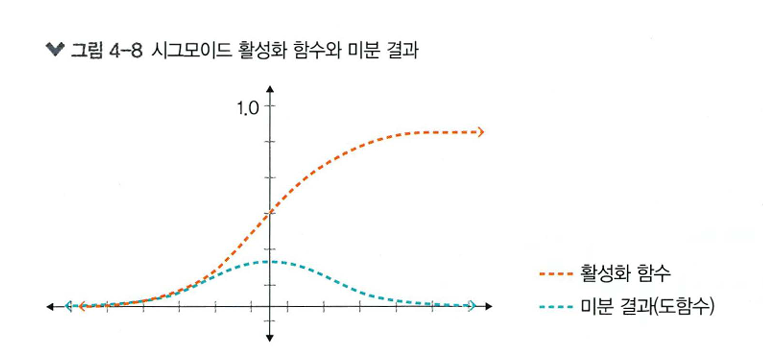

하이퍼볼릭 탄젠트 함수

- 선형 함수의 결과를 -1~1 사이에서 비선형 형태로 변형
- 양수 편향 문제는 해결되었지만 기울기 소멸 문제는 여전히 발생

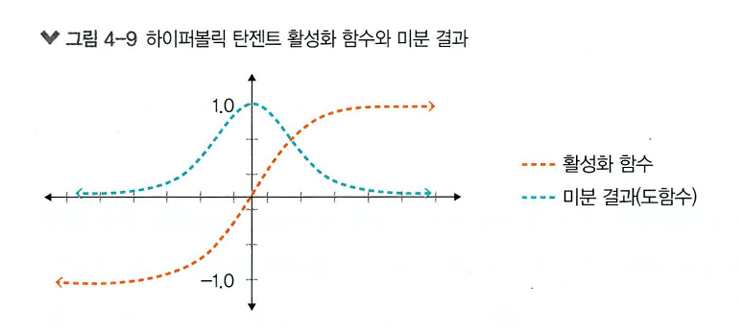

렐루 함수

- 입력(x)이 음수일 때는 0을 출력하고, 양수일 때는 x를 출력함

- 경사 하강법에 영향을 주지 않아 학습 속도가 빠르고, 기울기 소면 문제가 발생하지 않는 장점이 있음

- 일반적으로 은닉층에서 사용되며, 하이퍼볼릭 탄젠트 함수 대비 학습 속도가 6배 빠름.

- 문제는 음수 값을 입력받으면 항상 0을 출력하기 때문에 학습 능력이 감소하는데, 이를 해결하려고 리키 렐루 함수 등을 사용함

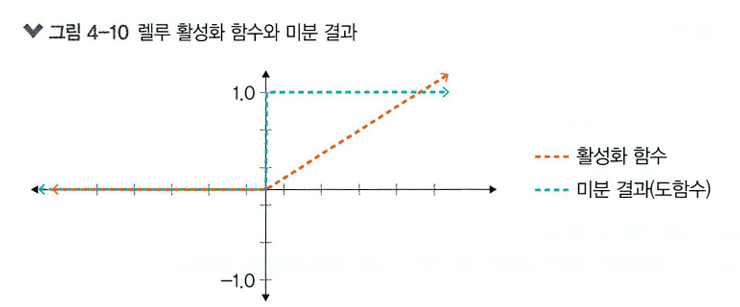

리키 렐루 함수
- 입력 값이 음수이면 0이 아닌 0.0001처럼 매우 작은 수를 반환
- 입력 값이 수렴하는 구간이 제거됨.

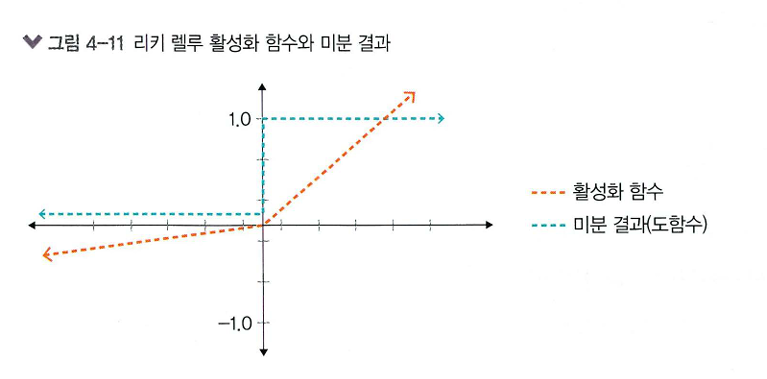

소프트맥스 함수

- 입력 값을 0~1사이에 출력되도록 정규화하여 출력 값들의 총합이 항상 1이 되도록 함.



In [2]:
#렐루 함수 / 소프트 맥스 함수 구현
class Net(torch.nn.Module):
  def __init__(self, n_feature, n_hidden, n_output):
    super(Net, self).__init__()
    self.hidden = torch.nn.Linear(n_feature, n_hidden)
    self.relu = torch.nn.ReLU(inplace=True)
    self.out = torch.nn.Linear(n_hidden, n_output)
    self.softmax = torch.nn.Softmax(dim=n_output)
  def forward(self, x):
    x = self.hidden(x)
    x = self.relu(x)
    x = self.out(x)
    x = self.softmax(x)
    return x

손실 함수
- 학습을 통해 얻은 데이터의 추정치가 실제 데이터와 얼마나 차이가 나는지 평가하는 지표
- 클수록 많이 틀렸다. 0에 가까울수록 완벽하게 추정할 수 있다.
- MSE, CEE

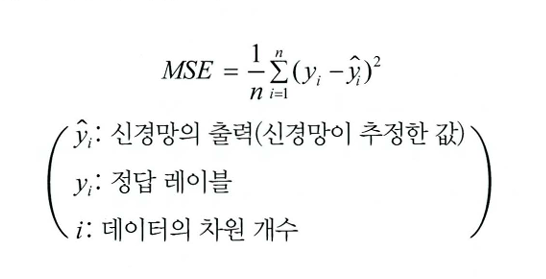

In [4]:
"""
import torch

loss_fn = torch.nn.MSELoss(reduction='sum')
y_pred = model(x)
loss = loss_fn(y_pred, y)
"""

"\nimport torch\n\nloss_fn = torch.nn.MSELoss(reduction='sum')\ny_pred = model(x)\nloss = loss_fn(y_pred, y)\n"

크로스 엔트로피 오차
 - 분류 문제에서 원-핫 인코딩 했을 때 사용할 수 있는 오차 계산법
- 평균 제곱 오차 손실 함수와 시그모이드 활성화 함수를 결합하여 사용하면 시그모이드의 특성으로 기울기가 매끄럽지 못한 울퉁불퉁한 상태이며 학습 속도도 매우 늦는데 이를 극복
- 두 개의 확률 분포 차이를 이용하기 때문에 시그모이드의 영향을 덜 받음 -> 빠른 학습 속도

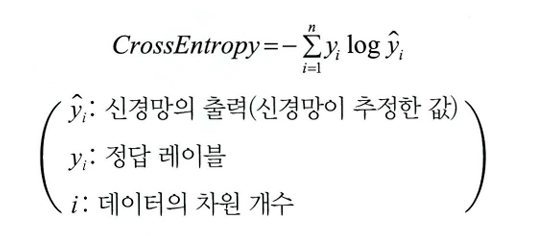

In [5]:
#크로스 엔트로피 오차 구현
'''
loss = nn.CrossEntropyLoss()
input = torch.randn(5, 6, requires_grad=True)
target = torch.empty(3, dtype=torch.long).random_(5)
output = loss(input, target)
output.backward()
'''

'\nloss = nn.CrossEntropyLoss()\ninput = torch.randn(5, 6, requires_grad=True)\ntarget = torch.empty(3, dtype=torch.long).random_(5)\noutput = loss(input, target)\noutput.backward()\n'

순전파/역전파

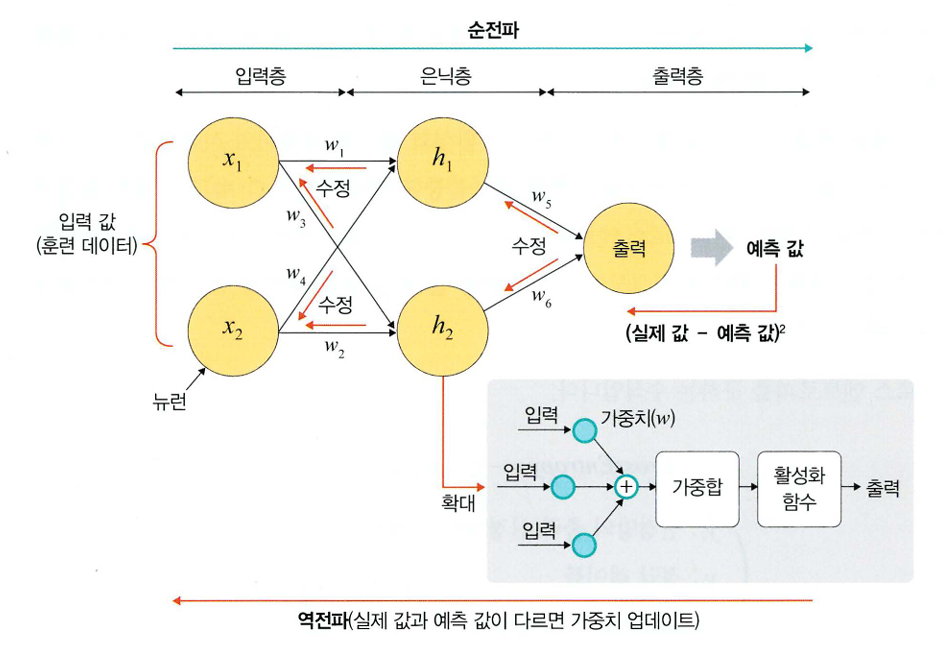

### 딥러닝의 문제점과 해결 방안

과적합 문제 발생

과적합(over-fitting): 훈련 데이터를 과하게 학습해서 발생. 일반적으로 훈련 데이터는 실제 데이터의 일부분

과적합을 해결하는 방법으로 드롭아웃이 있음

In [6]:
#드롭아웃 구현
class DropoutModel(torch.nn.Module):
  def __init__(self):
    super(DropoutModel, self).__init__()
    self.layer1 = torch.nn.Linear(784, 1200)
    self.dropout1 = torch.nn.Dropout(0.5)
    self.layer2 = torch.nn.Linear(1200, 1200)
    self.dropout2 = torch.nn.Dropout(0.5)
    self.layer3 = torch.nn.Linear(1200, 10)

  def forward(self, x):
    x = F.relu(self.layer1(x))
    x = self.dropout1(x)
    x = F.relu(self.layer2(x))
    x = self.dropout2(x)
    return self.layer3(x)

In [7]:
#미니 배치 경사 하강법 구현
'''
class CustomDataset(Dataset):
  def __init__(self):
    self.x_data = [[1, 2, 3], [4, 5, 6], [7, 8, 9]]
    self.y_data = [[12], [18], [11]]
    def __len__(self):
      return len(self.x_data)
    def __getitem__(self, idx):
      x = torch.FloatTensor(self.x_data[idx])
      y = torch.FloatTensor(self.y_data[idx])
      return x, y
dataset = CustomDataset()
dataloader = DataLoader(
    dataset,
    batch_size=2,
    shuffle=True,
)
'''

'\nclass CustomDataset(Dataset):\n  def __init__(self):\n    self.x_data = [[1, 2, 3], [4, 5, 6], [7, 8, 9]]\n    self.y_data = [[12], [18], [11]]\n    def __len__(self):\n      return len(self.x_data)\n    def __getitem__(self, idx):\n      x = torch.FloatTensor(self.x_data[idx])\n      y = torch.FloatTensor(self.y_data[idx])\n      return x, y\ndataset = CustomDataset()\ndataloader = DataLoader(\n    dataset,\n    batch_size=2,\n    shuffle=True,\n)\n'

In [8]:
'''
#아다그라드
optimizer = torch.optim.Adagrad(model.parameters(), lr=0.01)

#아다델타
optimizer = torch.optim.Adadelta(model.parameters(), lr=1.0)

#알엠에스프롭
optimizer = torch.optim.RMSprop(model.parameters(), lr=0.01)

#모멘텀
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)

#네스테로프 모멘텀
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9, nesterov=True)

#아담
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
'''

'\n#아다그라드\noptimizer = torch.optim.Adagrad(model.parameters(), lr=0.01)\n\n#아다델타\noptimizer = torch.optim.Adadelta(model.parameters(), lr=1.0)\n\n#알엠에스프롭\noptimizer = torch.optim.RMSprop(model.parameters(), lr=0.01)\n\n#모멘텀\noptimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)\n\n#네스테로프 모멘텀\noptimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9, nesterov=True)\n\n#아담\noptimizer = torch.optim.Adam(model.parameters(), lr=0.01)\n'

### 4-3. 딥러닝 알고리즘
심층 신경망을 사용한다는 공통점을 가짐

합성곱 신경망(CNN), 순환 신경망(RNN), 심층 신뢰 신경망(DBN)으로 분류

4.3.1. 심층 신경망

- 심층 신경망(DNN) 입력층과 출력층 사이에 다수의 은닉층을 포함하는 인공 신경망. - 다양한 비선형적 관계를 학습할 수 있는 장점이 있지만 학습을 위한 연산량이 많고 기울기 소멸 문제 등이 발생할 수 있음.

4-3-2. 합성곱 신경망
- 합성곱층과 풀링층을 포함하는 이미지 처리 성능이 좋은 인공 신경망 알고리즘으로, 영상 및 사진이 포함된 데이터에서 객체를 탐색하거나 객체 위치를 찾아내는 데 유용한 신경망
- 객체, 얼굴, 장면을 인식하기 위한 패턴을 찾는 데 유용하며, LeNet-5, AlexNet, VGG, GoogLeNet, ResNet 등이 있음
- '각 층의 입출력 향상을 유지, 이미지 공간 정보를 유지하면서 인접 이미지와 차이가 있는 특징을 효과적으로 인식, 복수 필터로 이미지의 특징을 추출하고 학습, 추출한 이미지의 특징을 모으고 강화하는 풀링층 존재, 필터를 공유 파라미터로 사용하기 때문에 일반 인공 신경망과 비교하여 학습 파라미터가 적다'는 차별성을 갖춤

4.3.3. 순환 신경망
- 시계열 데이터 같은 시간 흐름에 따라 변화하는 데이터를 학습하기 위한 인공 신경망.
- 시간성(temporal property)을 가진 데이터가 많음. 데이터는 동적이고 길이가 가변적임.
- 기울기 소멸 문제가 있으며 LSTM으로 해결하고자 함.
- 자연어 처리 분야에서 주로 쓰임.

4.3.4 제한된 볼츠만 머신

- 가시층과 은닉층으로 구성된 모델
- 차원 감소, 분류, 선형 회귀 분석, 협업 필터링, 특성 값 학습, 주제 모델링에 사용
기울기 소멸 문제를 해결하기 위해 사전 학습 용도로 활용 가능
- 심층 신뢰 신경망의 요소로 활용

4.3.5. 심층 신뢰 신경망
- 제한된 볼츠만 머신을 블록처럼 여러 층으로 쌓은 형태로 연결된 신경망.
- 레이블이 없는 데이터에 대한 비지도 학습 가능
- 순차적으로 학습시켜가면서 계층적 구조 생성. 위로 올라갈수록 추상적 특성을 추출함.